# 1. Selección del conjunto de datos

## 1.1. Elección y justificación
He elegido **Intel Image Classification**, disponible en Kaggle con el identificador `puneet6060/intel-image-classification`.

El objetivo es asignar cada imagen a una de seis categorías: edificios (`buildings`), bosque (`forest`), glaciar (`glacier`), montaña (`mountain`), mar (`sea`) y calle (`street`). La variable objetivo es la categoría indicada por la carpeta.

Este problema permite comparar una CNN desde cero con una red preentrenada, porque contiene escenas con diferencias de color, textura y estructura, además de categorías que pueden confundirse, como montaña y glaciar o edificios y calle. La organización por clases facilita su posterior carga con TensorFlow/Keras.

El conjunto dispone de particiones etiquetadas de entrenamiento y test. En este apartado se comprueba su volumen real para valorar su utilidad para el entrenamiento y la evaluación, sin presuponer un rendimiento. Las imágenes sin etiqueta de `seg_pred`, si existen, se contabilizan aparte y no se utilizan para evaluar.

Fuente del conjunto: [Intel Image Classification en Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).

## 1.2. Dependencias

In [1]:
%pip install -q --upgrade kaggle
%pip install -q pandas pillow matplotlib tqdm

In [2]:
import os
import sys
import json
import hashlib
import subprocess
import importlib.util
from pathlib import Path
from getpass import getpass
from datetime import datetime, timezone
from importlib.metadata import version
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

SEMILLA = 42
CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
NOMBRES = dict(zip(CLASES, ['Edificios', 'Bosque', 'Glaciar', 'Montaña', 'Mar', 'Calle']))
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

## 1.3. Carga local o descarga autenticada

Primero descargamos de Kaggle una sola vez el dataset. Se hace de manera segura y se implementa un poco más la complejidad para garantizar la anonimidad del token utilizado.

In [3]:
DATASET = 'puneet6060/intel-image-classification'
DATOS = Path.cwd() / 'apartado1' / 'datos'
DATOS.mkdir(parents=True, exist_ok=True)

# Introducimos el token sin mostrarlo ni guardarlo en el notebook.
token = getpass.getpass('Introduce tu token de Kaggle: ').strip()

if not token:
    raise ValueError('No se ha introducido ningún token.')

# Pasamos la credencial únicamente al proceso de descarga.
entorno = os.environ.copy()
entorno['KAGGLE_API_TOKEN'] = token

try:
    # Localizamos el cliente instalado en el entorno del notebook.
    spec = importlib.util.find_spec('kaggle')

    if spec is None or not spec.submodule_search_locations:
        raise RuntimeError('Ejecuta primero la celda de instalación de Kaggle.')

    cli = Path(next(iter(spec.submodule_search_locations))) / 'cli.py'

    if not cli.is_file():
        raise RuntimeError('No se encuentra el cliente de Kaggle. Reinstala el paquete.')

    # Descargamos y descomprimimos las imágenes en la carpeta local.
    comando = [
        sys.executable, str(cli),
        'datasets', 'download',
        '-d', DATASET,
        '-p', str(DATOS),
        '--unzip'
    ]

    print('Descargando y descomprimiendo el dataset...')

    proceso = subprocess.run(
        comando,
        env=entorno,
        capture_output=True,
        text=True
    )

    if proceso.returncode != 0:
        mensaje = proceso.stderr or proceso.stdout or 'Sin detalle del error.'
        mensaje = mensaje.replace(token, '[TOKEN OCULTO]')
        raise RuntimeError('La descarga ha fallado:\n' + mensaje[-2500:])

    print('Dataset descargado en:', DATOS.relative_to(Path.cwd()).as_posix())

finally:
    # Retiramos la credencial de las variables utilizadas para la descarga.
    entorno.pop('KAGGLE_API_TOKEN', None)
    del token

Introduce tu token de Kaggle: ··········
Descargando y descomprimiendo el dataset...
Dataset descargado en: apartado1/datos


Para el uso de todos los compañeros, se cogen los datos del paquete con las carpetas predefinidas.

In [4]:
# Se crean variables para la utilización de las carpetas locales de cada uno.
BASE = Path.cwd() / 'apartado1'
DATOS = BASE / 'datos'
SALIDAS = BASE / 'resultados'
SALIDAS.mkdir(parents=True, exist_ok=True)

# Se crea el diccionario para las imagenes y clases.
CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
NOMBRES = dict(zip(
    CLASES,
    ['Edificios', 'Bosque', 'Glaciar', 'Montaña', 'Mar', 'Calle']
))
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

carpetas = {
    'train': DATOS / 'seg_train' ,
    'test': DATOS / 'seg_test'
}

print('Dataset local localizado:')
for parte, carpeta in carpetas.items():
    print(f'{parte}: {carpeta.relative_to(Path.cwd()).as_posix()}')

Dataset local localizado:
train: apartado1/datos/seg_train
test: apartado1/datos/seg_test


## 1.4. Inspección de todas las imágenes
Se registran dimensiones originales, modo de color, canales y formato. Las imágenes ilegibles se documentan sin modificar los originales. La huella SHA-256 permite revisar duplicados exactos de archivo, no todas las imágenes visualmente similares.

In [6]:
# Recogemos las imágenes de entrenamiento y test de cada clase.
archivos = [
    (parte, clase, ruta)
    for parte, carpeta in carpetas.items()
    for clase in CLASES
    for ruta in sorted((carpeta / clase).rglob('*'))
    if ruta.is_file() and ruta.suffix.lower() in EXT
]

registros = []
errores = []

# Abrimos las imágenes y registramos sus características.
for parte, clase, ruta in tqdm(archivos, desc='Inspección de imágenes'):
    ruta_relativa = ruta.relative_to(DATOS).as_posix()

    try:
        with Image.open(ruta) as imagen:
            imagen.load()

            registro = {
                'particion': parte,
                'clase': clase,
                'ruta': str(ruta),
                'ruta_relativa': ruta_relativa,
                'ancho': imagen.width,
                'alto': imagen.height,
                'modo': imagen.mode,
                'canales': len(imagen.getbands()),
                'formato': imagen.format
            }

        # Calculamos la huella para comprobar duplicados más adelante.
        registro['sha256'] = hashlib.sha256(ruta.read_bytes()).hexdigest()
        registros.append(registro)

    except Exception as exc:
        errores.append({
            'particion': parte,
            'clase': clase,
            'ruta_relativa': ruta_relativa,
            'error': type(exc).__name__
        })

# Creamos las tablas y guardamos los archivos que no se han podido leer.
datos = pd.DataFrame(registros)

errores_df = pd.DataFrame(
    errores,
    columns=['particion', 'clase', 'ruta_relativa', 'error']
)
errores_df.to_csv(SALIDAS / 'ilegibles.csv', index=False)

# Contamos las imágenes válidas por clase y partición.
tabla = pd.crosstab(
    datos['clase'], datos['particion']
).reindex(index=CLASES, columns=['train', 'test'], fill_value=0)

# Contamos por separado las imágenes sin etiqueta.
sin_etiqueta = sum(
    1
    for ruta in DATOS.rglob('*')
    if ruta.is_file()
    and ruta.suffix.lower() in EXT
    and 'seg_pred' in ruta.relative_to(DATOS).parts
)

print('Archivos etiquetados:', len(archivos))
print('Imágenes válidas:', len(datos))
print('Archivos ilegibles:', len(errores_df))
print('Imágenes sin etiqueta en seg_pred:', sin_etiqueta)

display(pd.DataFrame({
    'Clase': CLASES,
    'Significado': [NOMBRES[clase] for clase in CLASES]
}))

if errores:
    display(errores_df.head(20))

Inspección de imágenes:   0%|          | 0/17034 [00:00<?, ?it/s]

Archivos etiquetados: 17034
Imágenes válidas: 17034
Archivos ilegibles: 0
Imágenes sin etiqueta en seg_pred: 7301


,Clase,Significado
0,buildings,Edificios
1,forest,Bosque
2,glacier,Glaciar
3,mountain,Montaña
4,sea,Mar
5,street,Calle


## 1.5. Análisis y tratamiento de duplicados

A partir de las huellas SHA-256 calculadas durante la inspección del conjunto de datos, se comprueba si existen archivos exactamente duplicados.

La presencia de una misma imagen en las particiones de entrenamiento y test puede provocar fuga de información, ya que el modelo podría ser evaluado utilizando una imagen que ya ha observado durante el entrenamiento.

También se comprueba si una misma imagen aparece asociada a clases diferentes, pues esto representaría una inconsistencia en el etiquetado.

Para evitar modificar el conjunto de datos original, la limpieza se realiza sobre el DataFrame generado durante la inspección. Como resultado se crea `datos_limpios`, que contiene las imágenes que se utilizarán en los análisis y entrenamientos posteriores.

### 1.5.1. Detección de duplicados

In [7]:
# Seleccionamos todas las imágenes cuya huella SHA-256 aparece más de una vez.
duplicados = (
    datos[
        datos.duplicated(
            subset='sha256',
            keep=False
        )
    ]
    .sort_values(
        ['sha256', 'particion', 'clase', 'ruta_relativa']
    )
    .copy()
)

# Creamos un resumen de cada grupo de imágenes duplicadas.
resumen_duplicados = (
    duplicados.groupby('sha256')
    .agg(
        numero_imagenes=('ruta_relativa', 'size'),
        numero_particiones=('particion', 'nunique'),
        numero_clases=('clase', 'nunique'),
        particiones=(
            'particion',
            lambda valores: ', '.join(sorted(set(valores)))
        ),
        clases=(
            'clase',
            lambda valores: ', '.join(sorted(set(valores)))
        )
    )
    .reset_index()
)

# Clasificamos cada grupo según el tipo de duplicidad detectado.
def clasificar_duplicado(fila):
    if fila['numero_clases'] > 1:
        return 'Etiquetas contradictorias'

    if fila['numero_particiones'] > 1:
        return 'Duplicado entre train y test'

    return 'Duplicado dentro de la misma partición'


if not resumen_duplicados.empty:
    resumen_duplicados['tipo'] = resumen_duplicados.apply(
        clasificar_duplicado,
        axis=1
    )
else:
    resumen_duplicados['tipo'] = pd.Series(dtype='object')

# Calculamos los principales resultados.
numero_grupos = len(resumen_duplicados)
numero_imagenes = len(duplicados)

grupos_entre_particiones = (
    resumen_duplicados['numero_particiones'].gt(1).sum()
)

grupos_con_etiquetas_contradictorias = (
    resumen_duplicados['numero_clases'].gt(1).sum()
)

porcentaje_duplicadas = (
    100 * numero_imagenes / len(datos)
    if len(datos) > 0
    else 0
)

print('Grupos de duplicados exactos:', numero_grupos)
print('Imágenes incluidas en esos grupos:', numero_imagenes)
print(
    'Porcentaje de imágenes incluidas en grupos duplicados:',
    f'{porcentaje_duplicadas:.2f}%'
)
print(
    'Grupos presentes en train y test:',
    grupos_entre_particiones
)
print(
    'Grupos con etiquetas contradictorias:',
    grupos_con_etiquetas_contradictorias
)

display(resumen_duplicados)

Grupos de duplicados exactos: 18
Imágenes incluidas en esos grupos: 36
Porcentaje de imágenes incluidas en grupos duplicados: 0.21%
Grupos presentes en train y test: 3
Grupos con etiquetas contradictorias: 13


,sha256,numero_imagenes,numero_particiones,numero_clases,particiones,clases,tipo
0,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,2,1,2,train,"buildings, street",Etiquetas contradictorias
1,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,2,2,2,"test, train","buildings, street",Etiquetas contradictorias
2,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias
3,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias
4,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,2,1,1,train,forest,Duplicado dentro de la misma partición
5,4f93f75b82d15e088b08ab1ba544de749e139437628d9b...,2,2,2,"test, train","buildings, street",Etiquetas contradictorias
6,5df7ef50dcb17f18dce56d30afcb45e2e00e610421051f...,2,1,1,train,street,Duplicado dentro de la misma partición
7,7823265cfabfe064e9c63afeb438932e476df252e07f71...,2,1,1,train,street,Duplicado dentro de la misma partición
8,8abeea822034f73fc5c499b11e1f893ee0144e48055a5f...,2,1,2,train,"mountain, sea",Etiquetas contradictorias
9,8ff16db30c2e6742a953797dcfa43cad0e07fc420b0538...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias


### 1.5.2. Decisión de limpieza

El tratamiento aplicado depende del tipo de duplicidad detectado:

1. Si una imagen aparece varias veces dentro de la misma clase y partición, se conserva únicamente una copia.
2. Si una imagen aparece en entrenamiento y test con la misma clase, se conserva una copia de entrenamiento y se excluyen las copias de test. De esta forma se evita la fuga de información durante la evaluación.
3. Si una imagen idéntica aparece asociada a clases diferentes, se excluye el grupo completo. Se adopta esta decisión conservadora porque no puede determinarse automáticamente cuál de las etiquetas es correcta.

Los archivos originales no se eliminan ni se modifican. La exclusión se realiza únicamente en el DataFrame utilizado en las etapas posteriores.

In [8]:
# Guardamos los índices que deben excluirse del conjunto definitivo.
indices_excluir = set()

# Registramos la decisión tomada para cada imagen duplicada.
decisiones = []

for sha256, grupo in duplicados.groupby('sha256'):

    grupo = grupo.sort_values(
        ['particion', 'clase', 'ruta_relativa']
    )

    numero_clases = grupo['clase'].nunique()
    numero_particiones = grupo['particion'].nunique()

    # Caso 1: la misma imagen aparece asociada a clases diferentes.
    if numero_clases > 1:
        for indice, fila in grupo.iterrows():
            indices_excluir.add(indice)

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': 'Excluir',
                'motivo': 'Etiquetas contradictorias'
            })

    # Caso 2: la misma imagen aparece en train y test,
    # pero asociada a la misma clase.
    elif numero_particiones > 1:
        grupo_train = grupo[
            grupo['particion'] == 'train'
        ]

        # Conservamos solamente la primera copia de train.
        indice_conservar = grupo_train.index[0]

        for indice, fila in grupo.iterrows():
            if indice == indice_conservar:
                decision = 'Conservar'
                motivo = 'Copia seleccionada de train'
            else:
                indices_excluir.add(indice)
                decision = 'Excluir'
                motivo = 'Duplicado entre train y test'

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': decision,
                'motivo': motivo
            })

    # Caso 3: las copias están en la misma clase y partición.
    else:
        indice_conservar = grupo.index[0]

        for indice, fila in grupo.iterrows():
            if indice == indice_conservar:
                decision = 'Conservar'
                motivo = 'Primera copia del grupo'
            else:
                indices_excluir.add(indice)
                decision = 'Excluir'
                motivo = 'Duplicado en la misma partición'

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': decision,
                'motivo': motivo
            })

# Creamos una tabla con todas las decisiones tomadas.
decisiones_df = pd.DataFrame(
    decisiones,
    columns=[
        'sha256',
        'particion',
        'clase',
        'ruta_relativa',
        'decision',
        'motivo'
    ]
)

print('Imágenes que se conservarán dentro de los grupos duplicados:',
      (decisiones_df['decision'] == 'Conservar').sum())

print('Imágenes que se excluirán:',
      (decisiones_df['decision'] == 'Excluir').sum())

display(decisiones_df)


Imágenes que se conservarán dentro de los grupos duplicados: 5
Imágenes que se excluirán: 31


,sha256,particion,clase,ruta_relativa,decision,motivo
0,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,train,buildings,seg_train/buildings/5069.jpg,Excluir,Etiquetas contradictorias
1,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,train,street,seg_train/street/2764.jpg,Excluir,Etiquetas contradictorias
2,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,test,street,seg_test/street/21170.jpg,Excluir,Etiquetas contradictorias
3,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,train,buildings,seg_train/buildings/4634.jpg,Excluir,Etiquetas contradictorias
4,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,train,glacier,seg_train/glacier/16044.jpg,Excluir,Etiquetas contradictorias
5,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,train,mountain,seg_train/mountain/17775.jpg,Excluir,Etiquetas contradictorias
6,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,train,glacier,seg_train/glacier/10234.jpg,Excluir,Etiquetas contradictorias
7,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,train,mountain,seg_train/mountain/7654.jpg,Excluir,Etiquetas contradictorias
8,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,train,forest,seg_train/forest/15657.jpg,Conservar,Primera copia del grupo
9,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,train,forest,seg_train/forest/18807.jpg,Excluir,Duplicado en la misma partición


### 1.5.3 Creación dataset limpio

In [9]:
# Creamos el conjunto definitivo excluyendo las filas seleccionadas.
datos_limpios = (
    datos.drop(index=list(indices_excluir))
    .reset_index(drop=True)
    .copy()
)

imagenes_originales = len(datos)
imagenes_definitivas = len(datos_limpios)
imagenes_excluidas = imagenes_originales - imagenes_definitivas

print('Imágenes válidas antes de la limpieza:', imagenes_originales)
print('Imágenes excluidas:', imagenes_excluidas)
print('Imágenes válidas después de la limpieza:', imagenes_definitivas)

Imágenes válidas antes de la limpieza: 17034
Imágenes excluidas: 31
Imágenes válidas después de la limpieza: 17003


In [10]:
# Guardamos el inventario definitivo de imágenes.
datos_limpios.to_csv(
    SALIDAS / 'imagenes_limpias.csv',
    index=False
)

# Guardamos las decisiones aplicadas a los duplicados.
decisiones_df.to_csv(
    SALIDAS / 'tratamiento_duplicados.csv',
    index=False
)

# Guardamos también el resumen por grupos.
resumen_duplicados.to_csv(
    SALIDAS / 'resumen_duplicados.csv',
    index=False
)

print('Archivos generados:')
print('- resultados/imagenes_limpias.csv')
print('- resultados/tratamiento_duplicados.csv')
print('- resultados/resumen_duplicados.csv')

Archivos generados:
- resultados/imagenes_limpias.csv
- resultados/tratamiento_duplicados.csv
- resultados/resumen_duplicados.csv


### 1.5.4 Validación de limpieza
Por último solo falta comprobar que la limpieza ha sido correcta.

In [11]:
# Comprobamos si queda alguna huella repetida.
duplicados_restantes = (
    datos_limpios[
        datos_limpios.duplicated(
            subset='sha256',
            keep=False
        )
    ]
)

# Comprobamos si alguna huella sigue apareciendo
# simultáneamente en train y test.
grupos_restantes_entre_particiones = (
    datos_limpios.groupby('sha256')['particion']
    .nunique()
    .gt(1)
    .sum()
)

# Comprobamos si alguna huella sigue asociada
# a más de una clase.
grupos_restantes_entre_clases = (
    datos_limpios.groupby('sha256')['clase']
    .nunique()
    .gt(1)
    .sum()
)

print(
    'Imágenes pertenecientes a grupos duplicados restantes:',
    len(duplicados_restantes)
)
print(
    'Grupos todavía presentes en train y test:',
    grupos_restantes_entre_particiones
)
print(
    'Grupos todavía asociados a clases diferentes:',
    grupos_restantes_entre_clases
)

if (
    duplicados_restantes.empty
    and grupos_restantes_entre_particiones == 0
    and grupos_restantes_entre_clases == 0
):
    print('Validación correcta: no quedan duplicados exactos.')
else:
    print('Advertencia: todavía existen duplicados exactos.')

    display(
        duplicados_restantes[
            [
                'sha256',
                'particion',
                'clase',
                'ruta_relativa'
            ]
        ]
    )

Imágenes pertenecientes a grupos duplicados restantes: 0
Grupos todavía presentes en train y test: 0
Grupos todavía asociados a clases diferentes: 0
Validación correcta: no quedan duplicados exactos.


## 1.6. Número de imágenes y distribución de clases
Se muestran recuentos y porcentajes sobre imágenes válidas. La relación mayoritaria/minoritaria describe el desequilibrio observado.

particion,train,test,total,porcentaje_total,porcentaje_train,porcentaje_test
clase,,,,,,
buildings,2187,436,2623,15.43,15.61,14.55
forest,2269,474,2743,16.13,16.20,15.82
glacier,2398,552,2950,17.35,17.12,18.42
mountain,2504,525,3029,17.81,17.88,17.52
sea,2272,510,2782,16.36,16.22,17.02
street,2376,500,2876,16.91,16.96,16.68


Imágenes del conjunto limpio: 17003
Clases: 6
Relación mayoritaria/minoritaria: 1.15


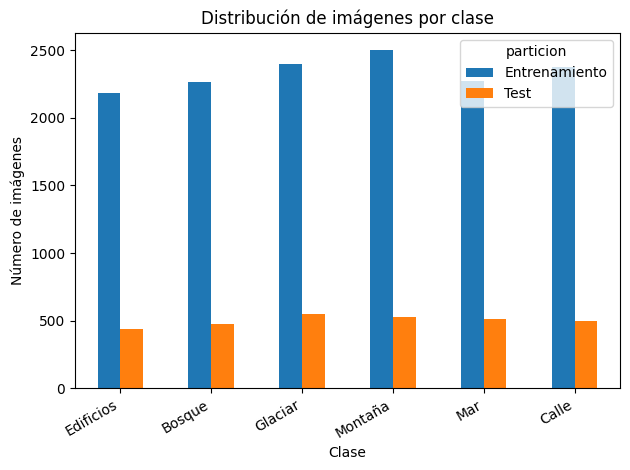

In [12]:
# Creamos la tabla a partir del conjunto limpio.
tabla = pd.crosstab(
    datos_limpios['clase'],
    datos_limpios['particion']
).reindex(
    index=CLASES,
    columns=['train', 'test'],
    fill_value=0
)

# Calculamos el total de imágenes y los porcentajes por clase.
tabla['total'] = tabla[['train', 'test']].sum(axis=1)

tabla['porcentaje_total'] = (
    100 * tabla['total'] / tabla['total'].sum()
).round(2)

for parte in ['train', 'test']:
    tabla[f'porcentaje_{parte}'] = (
        100 * tabla[parte] / tabla[parte].sum()
    ).round(2)

display(tabla)

# Comparamos el tamaño de la clase mayoritaria y la minoritaria.
ratio = tabla['total'].max() / tabla['total'].min()

print('Imágenes del conjunto limpio:', len(datos_limpios))
print('Clases:', datos_limpios['clase'].nunique())
print('Relación mayoritaria/minoritaria:', round(ratio, 2))

# Representamos las imágenes de entrenamiento y test por clase.
ax = (
    tabla[['train', 'test']]
    .rename(
        index=NOMBRES,
        columns={
            'train': 'Entrenamiento',
            'test': 'Test'
        }
    )
    .plot.bar()
)

ax.set_title('Distribución de imágenes por clase')
ax.set_xlabel('Clase')
ax.set_ylabel('Número de imágenes')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()

# Guardamos la gráfica en la carpeta de resultados.
plt.savefig(
    SALIDAS / 'distribucion_dataset_limpio.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

## 1.7. Dimensiones originales y canales
Se analizan las imágenes sin redimensionarlas. El tamaño de entrada de las redes se decidirá en los apartados posteriores.

,ancho,alto,canales
count,17003.0,17003.00,17003.0
mean,150.0,149.91,3.0
std,0.0,1.99,0.0
min,150.0,72.00,3.0
25%,150.0,150.00,3.0
50%,150.0,150.00,3.0
75%,150.0,150.00,3.0
max,150.0,150.00,3.0


,ancho,alto,imagenes
31,150,150,16948
11,150,113,7
20,150,135,3
10,150,111,3
8,150,108,2
9,150,110,2
1,150,76,2
2,150,81,2
19,150,134,2
24,150,142,2


Imágenes analizadas: 17003
Resoluciones diferentes: 32


,modo,canales,formato,imagenes
0,RGB,3,JPEG,17003


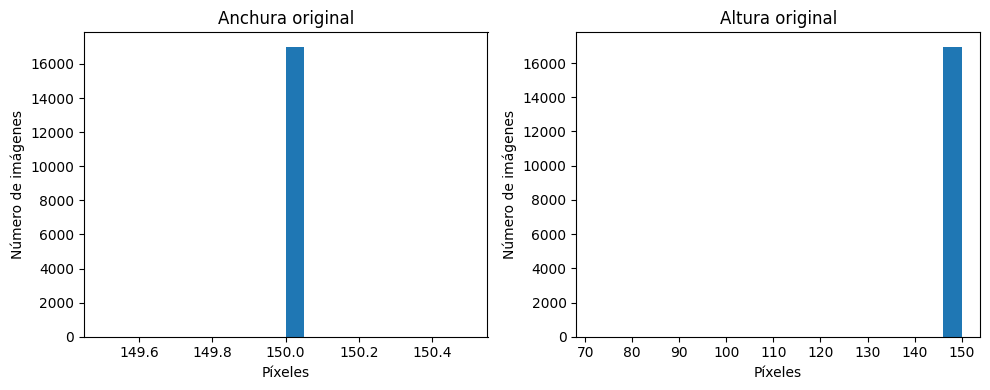

In [13]:
# Contamos las imágenes de cada resolución y ordenamos por frecuencia.
resoluciones = (
    datos_limpios.groupby(['ancho', 'alto'])
    .size()
    .rename('imagenes')
    .reset_index()
    .sort_values('imagenes', ascending=False)
)

# Mostramos las estadísticas de tamaño y las resoluciones más frecuentes.
display(
    datos_limpios[
        ['ancho', 'alto', 'canales']
    ].describe().round(2)
)

display(resoluciones.head(20))

print('Imágenes analizadas:', len(datos_limpios))
print('Resoluciones diferentes:', len(resoluciones))

# Contamos las imágenes según su modo de color, canales y formato.
caracteristicas = (
    datos_limpios.groupby(['modo', 'canales', 'formato'])
    .size()
    .rename('imagenes')
    .reset_index()
    .sort_values('imagenes', ascending=False)
)

display(caracteristicas)

# Representamos la distribución de anchuras y alturas originales.
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

for eje, campo, titulo in zip(
    ejes,
    ['ancho', 'alto'],
    ['Anchura original', 'Altura original']
):
    eje.hist(datos_limpios[campo], bins=20)
    eje.set_title(titulo)
    eje.set_xlabel('Píxeles')
    eje.set_ylabel('Número de imágenes')

plt.tight_layout()

# Guardamos la gráfica en la carpeta de resultados.
plt.savefig(
    SALIDAS / 'dimensiones_dataset_limpio.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# 1.7. Keras Datasets
Disponibilizar los datasets para ser utilizados en entrenamiento, validación y test

In [14]:
import tensorflow as tf
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomTranslation, RandomZoom, RandomContrast, RandomBrightness

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
RANDOM_SEED = 1234
EPOCHS = 300

# para normalizar las imagenes [0,1]
def preprocess_normalization(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# dataset base con las imagenes para train
train_ds = tf.keras.utils.image_dataset_from_directory(
    carpetas["train"],
    validation_split=0.2,
    subset="training",
    seed=RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

# data augmentation (solo usar en train)
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(factor=0.01, fill_mode="reflect"),
    RandomZoom(height_factor=0.2, width_factor=0.2, fill_mode="reflect"),
    RandomContrast(factor=0.5, value_range=(0, 255)),
    RandomBrightness(factor=0.05, value_range=(0, 255))
])
def preprocess_data_augmentation(image, label):
    image = data_augmentation(image, training=True )
    return image, label

# dataset de train con data augmentation
train_ds_augmented = (
    train_ds
    .map(preprocess_data_augmentation, num_parallel_calls=tf.data.AUTOTUNE)
)

# dataset base con las imagenes para validación
val_ds = tf.keras.utils.image_dataset_from_directory(
    carpetas["train"],
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

# dataset base con las imagenes para test
test_ds = tf.keras.utils.image_dataset_from_directory(
    carpetas["test"],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


### Verificar que el data augmentation produzca imágenes válidas

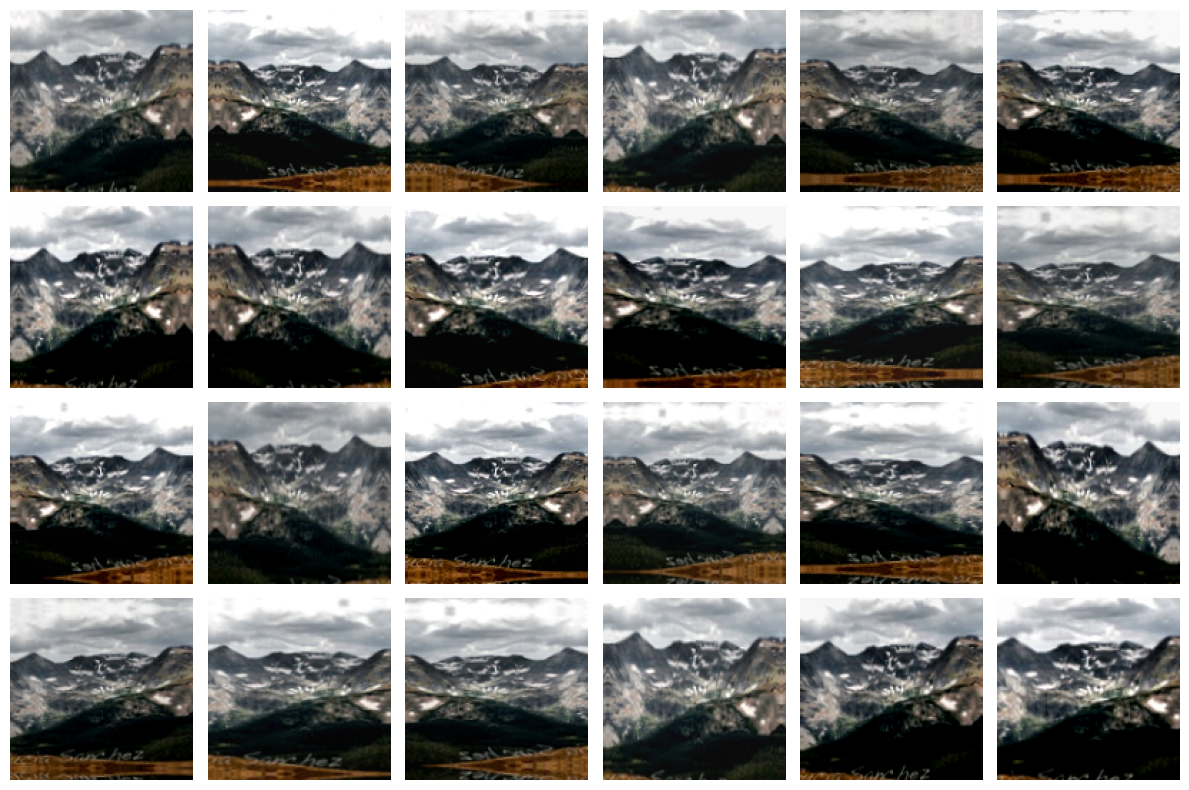

In [15]:
fig, axes = plt.subplots(4, 6, figsize=(12, 8))

for image, label in train_ds:
    break
for i, ax in enumerate(axes.flat):
    augmented_image = data_augmentation(image, training=True )
    ax.imshow(augmented_image[0] / 255)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Verificar los datasets

train


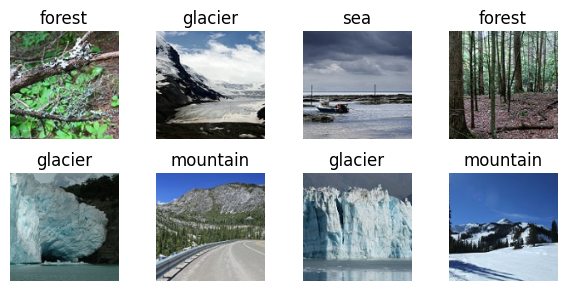

train - augmented


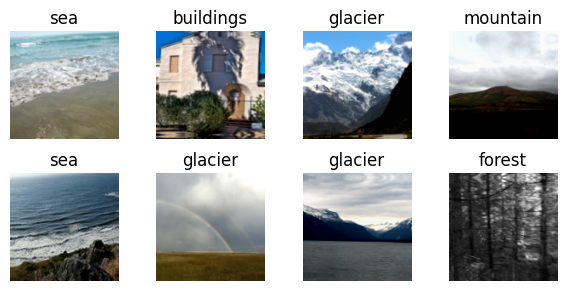

validation


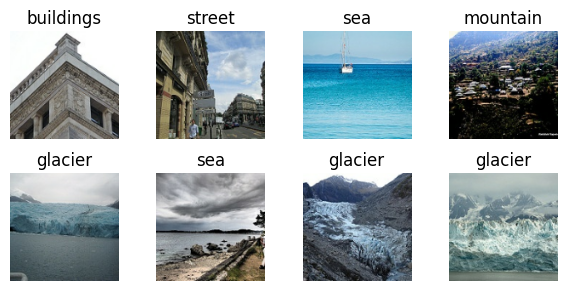

test


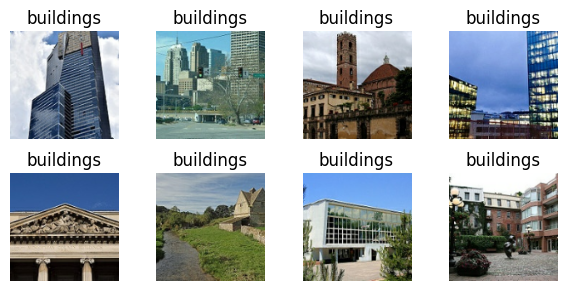

In [16]:
import matplotlib.pyplot as plt

def plot_sample(dataset):
    fig, axes = plt.subplots(2, 4, figsize=(6, 3))
    images, labels = next(iter(dataset.take(1)))

    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i].numpy() / 255)
        label = class_names[labels[i].numpy()]
        ax.set_title(label)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print('train')
plot_sample(train_ds)
print('train - augmented')
plot_sample(train_ds_augmented)
print('validation')
plot_sample(val_ds)
print('test')
plot_sample(test_ds)

## 2. Modelos de clasificación

In [17]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, GlobalAveragePooling2D, BatchNormalization, Dropout, ReLU, Add
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

MODELS = Path.cwd() / 'models'
MODELS.mkdir(parents=True, exist_ok=True)


## 2.1 Modelo Base

Clase base donde se implementarán los métodos que se reutilizarán en el resto de las implementaciones
* build: Crea el Model
* train: Entrena el modelo
* load: Recupera los pesos e imagen de resultados
* save: Almacena los pesos e imagen de resultados
* plot_history: Crea la imagen del entrenamiento
* show_history: Muestra la imagen del entrenamiento
* evaluate: Evalua el modelo con el dataset de test
* display_confusion_matrix: Construye la matriz de confusión
* print_classification_report: Imprime las métricas



In [18]:
class base_model:
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        self.name = name
        self.epochs = epochs
        self.batch_size = batch_size
        self.train_ds = train_ds
        self.val_ds = val_ds
        self.test_ds = test_ds
        self.model = None

    def build(self):
        raise Exception("Implementar build")

    def train(self):
        # callback para que pare si no mejora en 20 epochs
        early_stopping = EarlyStopping(monitor="val_accuracy", patience=20, mode="max", restore_best_weights=True)
        # callback para que reduzca el learningrate si no mejora en 10 epochs
        reduce_lr = ReduceLROnPlateau(monitor="val_accuracy", mode="max", factor=0.1, patience=10, min_delta=1e-6, cooldown=1, min_lr=1e-10, verbose=0)
        # entrenar
        history = self.model.fit(x = self.train_ds,
                                 validation_data=self.val_ds,
                                 epochs=self.epochs,
                                 batch_size = self.batch_size,
                                 callbacks=[early_stopping, reduce_lr])
        # almacenar el mejor modelo (solo pesos)
        self.model.save_weights(MODELS / f"{self.name}.weights.h5")
        # dibujar metricas
        self.plot_history(history)

    def load(self):
        # verificar que esté construido
        if self.model is None:
            self.build()
        pesos = MODELS / f"{self.name}.weights.h5"
        if os.path.exists(pesos):
            # cargar los pesos
            self.model.load_weights(pesos)
            return True
        return False

    def plot_history(self, H):
        epochs = len(H.history["loss"])
        plt.style.use("ggplot")
        plt.figure()
        plt.plot(np.arange(0, epochs), H.history["loss"], label="train_loss")
        plt.plot(np.arange(0, epochs), H.history["val_loss"], label="val_loss")
        plt.plot(np.arange(0, epochs), H.history["accuracy"], label="train_acc")
        plt.plot(np.arange(0, epochs), H.history["val_accuracy"], label="val_acc")
        plt.title("Training Loss and Accuracy")
        plt.xlabel("Epoch #")
        plt.ylabel("Loss/Accuracy")
        plt.legend()
        plt.savefig(MODELS / f"{self.name}.png")
        plt.close()

    def show_history(self):
        # cargar y dibujar la imagen
        image = Image.open(MODELS / f"{self.name}.png")
        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.axis('off')
        plt.show()

    def evaluate(self):
        y_true = np.concatenate([labels.numpy() for images, labels in self.test_ds])
        y_pred_prob = self.model.predict(self.test_ds)
        y_pred = np.argmax(y_pred_prob, axis=1)
        return y_true, y_pred

    def display_confusion_matrix(self, y_true, y_pred):
        cm = confusion_matrix(y_true, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
        fig, ax = plt.subplots(figsize=(6, 6))
        disp.plot(
            ax=ax,
            cmap='Blues',
            values_format='d',
            colorbar=False
        )
        plt.title(f"Matriz de Confusión - {self.name}")
        plt.tight_layout()
        plt.show()

    def print_classification_report(self, y_true, y_pred):
        print(classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            digits=4
        ))


## 2.2 Modelo CNN Simple


In [19]:
class simple_CNN_model(base_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        # se requiere normalización
        train_ds = (
            train_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(batch_size * 5)
            .prefetch(tf.data.AUTOTUNE)
        )
        # se requiere normalización
        val_ds = (
            val_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )
        # se requiere normalización
        test_ds = (
            test_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name,
                                               epochs = epochs,
                                               batch_size = batch_size,
                                               train_ds = train_ds,
                                               val_ds = val_ds,
                                               test_ds = test_ds)

    def build(self):
        inputs = Input(shape=(IMG_SIZE + (3,)))

        # CNN
        x = Conv2D(32, 3, activation='relu')(inputs)
        x = MaxPooling2D()(x)

        x = Conv2D(64, 3, activation='relu')(x)
        x = MaxPooling2D()(x)

        x = Conv2D(128, 3, activation='relu')(x)
        x = GlobalAveragePooling2D()(x)

        x = Dense(64, activation='relu')(x)

        outputs = Dense(len(class_names), activation='softmax')(x)
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()



In [20]:
# version simple CNN
simple_CNN = simple_CNN_model(name = "simple_CNN",
                              epochs=EPOCHS,
                              batch_size=BATCH_SIZE,
                              train_ds = train_ds,
                              val_ds = val_ds,
                              test_ds = test_ds
                            )
simple_CNN.build()

Model: "simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 32s 58ms/step - accuracy: 0.4595 - loss: 1.2795 - val_accuracy: 0.5898 - val_loss: 1.0687 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.5727 - loss: 1.0328 - val_accuracy: 0.5976 - val_loss: 0.9751 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.6299 - loss: 0.9180 - val_accuracy: 0.6661 - val_loss: 0.8872 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.6690 - loss: 0.8508 - val_accuracy: 0.6661 - val_loss: 0.8462 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.7050 - loss: 0.7695 - val_accuracy: 0.6486 - val_loss: 0.9747 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7317 - loss: 0.7223 - val_accuracy: 0.7516 - val_loss: 0.6840 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.750

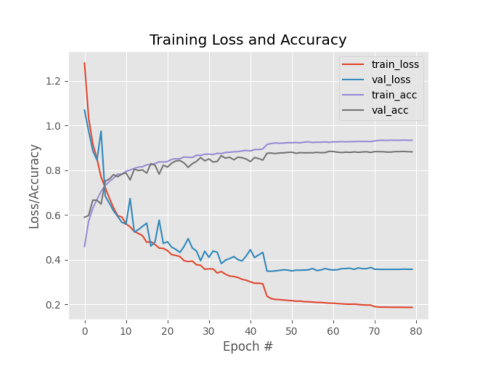

In [21]:
# Train
if not simple_CNN.load():
    simple_CNN.train()
simple_CNN.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step


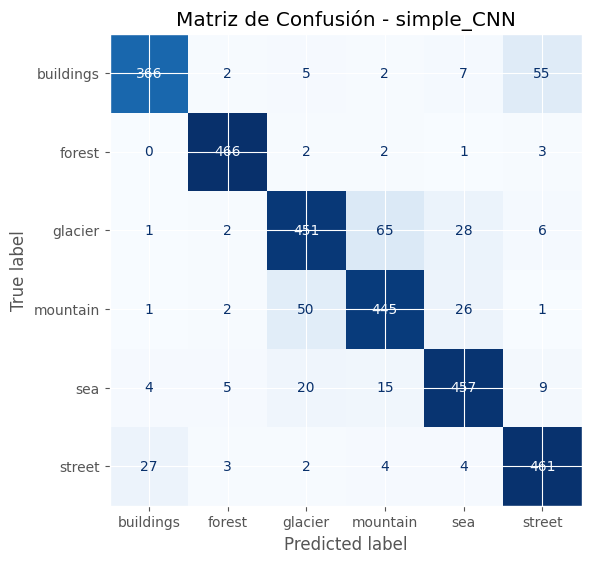

              precision    recall  f1-score   support

   buildings     0.9173    0.8375    0.8756       437
      forest     0.9708    0.9831    0.9769       474
     glacier     0.8509    0.8156    0.8329       553
    mountain     0.8349    0.8476    0.8412       525
         sea     0.8738    0.8961    0.8848       510
      street     0.8617    0.9202    0.8900       501

    accuracy                         0.8820      3000
   macro avg     0.8849    0.8833    0.8836      3000
weighted avg     0.8824    0.8820    0.8817      3000



In [22]:
# Evaluar
y_true, y_pred = simple_CNN.evaluate()
# Matriz de confusion
simple_CNN.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNN.print_classification_report(y_true, y_pred)

## 2.3 Modelo CNN Simple: Data Agumentation

In [23]:
# version simple CNN con Data Augmentation
simple_CNN_aug = simple_CNN_model(name = "simple_CNN_augmented",
                                  epochs=EPOCHS,
                                  batch_size=BATCH_SIZE,
                                  train_ds = train_ds_augmented,
                                  val_ds = val_ds,
                                  test_ds = test_ds)
simple_CNN_aug.build()

Model: "simple_CNN_augmented"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 49s 78ms/step - accuracy: 0.4778 - loss: 1.2329 - val_accuracy: 0.5745 - val_loss: 1.0182 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.5846 - loss: 1.0228 - val_accuracy: 0.6415 - val_loss: 0.9417 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.6256 - loss: 0.9440 - val_accuracy: 0.6875 - val_loss: 0.8682 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 73ms/step - accuracy: 0.6692 - loss: 0.8618 - val_accuracy: 0.7145 - val_loss: 0.7935 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 71ms/step - accuracy: 0.7032 - loss: 0.8028 - val_accuracy: 0.7010 - val_loss: 0.7850 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.7107 - loss: 0.7834 - val_accuracy: 0.7245 - val_loss: 0.7307 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.7

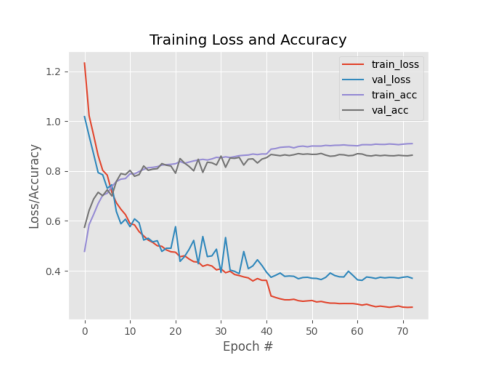

In [24]:
# Train
if not simple_CNN_aug.load():
    simple_CNN_aug.train()
simple_CNN_aug.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step


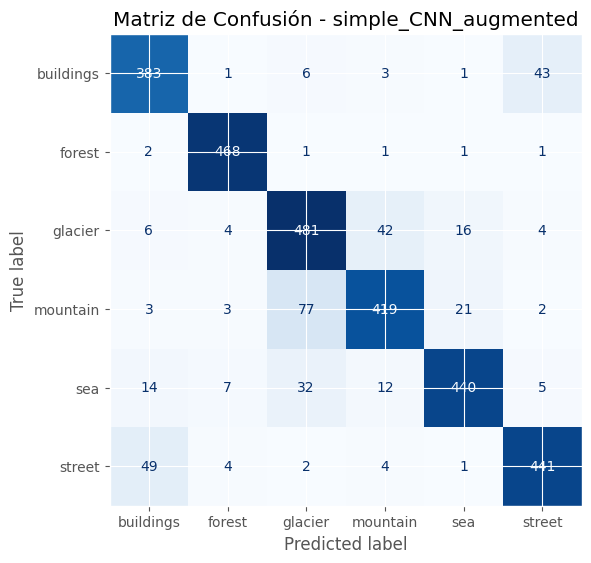

              precision    recall  f1-score   support

   buildings     0.8381    0.8764    0.8568       437
      forest     0.9610    0.9873    0.9740       474
     glacier     0.8030    0.8698    0.8351       553
    mountain     0.8711    0.7981    0.8330       525
         sea     0.9167    0.8627    0.8889       510
      street     0.8891    0.8802    0.8847       501

    accuracy                         0.8773      3000
   macro avg     0.8798    0.8791    0.8787      3000
weighted avg     0.8787    0.8773    0.8773      3000



In [25]:
# Evaluar
y_true, y_pred = simple_CNN_aug.evaluate()
# Matriz de confusion
simple_CNN_aug.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNN_aug.print_classification_report(y_true, y_pred)

## 2.4 Modelo CNN Simple v2: Regularización

* Dropout
* BatchNormalization


In [26]:
class simple_CNNv2_model(simple_CNN_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds, dropout_rate = 0.1):
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name,
                                               epochs = epochs,
                                               batch_size = batch_size,
                                               train_ds = train_ds,
                                               val_ds = val_ds,
                                               test_ds = test_ds)
        self.dropout_rate = dropout_rate

    def build(self):
        inputs = Input(shape=(IMG_SIZE + (3,)))

        # CNN
        x = Conv2D(32, 3)(inputs)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D()(x)

        x = Conv2D(64, 3)(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D()(x)

        x = Conv2D(128, 3)(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = GlobalAveragePooling2D()(x)
        x = Dropout(self.dropout_rate)(x)

        x = Dense(64, activation='relu')(x)
        x = Dropout(self.dropout_rate)(x)

        outputs = Dense(len(class_names), activation='softmax')(x)
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()

In [27]:
# version simple CNN v2 con regularización
simple_CNNv2 = simple_CNNv2_model(name = "simple_CNNv2",
                                  epochs=EPOCHS,
                                  batch_size=BATCH_SIZE,
                                  train_ds = train_ds,
                                  val_ds = val_ds,
                                  test_ds = test_ds)
simple_CNNv2.build()

Model: "simple_CNNv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,790 (401.52 KB)

 Trainable params: 102,342 (399.77 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 54ms/step - accuracy: 0.6280 - loss: 0.9490 - val_accuracy: 0.5470 - val_loss: 1.2291 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 26ms/step - accuracy: 0.7299 - loss: 0.7253 - val_accuracy: 0.5923 - val_loss: 1.0777 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.7532 - loss: 0.6649 - val_accuracy: 0.6319 - val_loss: 0.8916 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.7671 - loss: 0.6265 - val_accuracy: 0.3671 - val_loss: 2.2792 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7805 - loss: 0.6012 - val_accuracy: 0.5132 - val_loss: 1.6539 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.7923 - loss: 0.5640 - val_accuracy: 0.6611 - val_loss: 0.8249 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.80

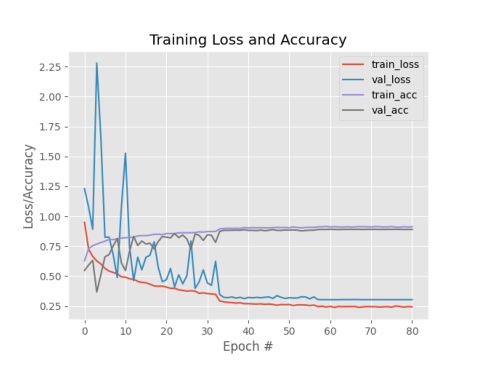

In [28]:
# train
if not simple_CNNv2.load():
    simple_CNNv2.train()
simple_CNNv2.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step


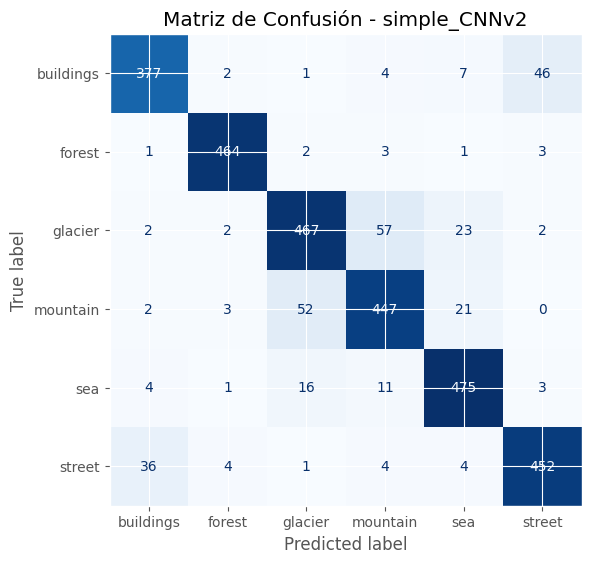

              precision    recall  f1-score   support

   buildings     0.8934    0.8627    0.8778       437
      forest     0.9748    0.9789    0.9768       474
     glacier     0.8664    0.8445    0.8553       553
    mountain     0.8498    0.8514    0.8506       525
         sea     0.8945    0.9314    0.9126       510
      street     0.8933    0.9022    0.8977       501

    accuracy                         0.8940      3000
   macro avg     0.8954    0.8952    0.8951      3000
weighted avg     0.8938    0.8940    0.8938      3000



In [29]:
# Evaluar
y_true, y_pred = simple_CNNv2.evaluate()
# Matriz de confusion
simple_CNNv2.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNNv2.print_classification_report(y_true, y_pred)

## 2.5 Modelo CNN con conexiones residuales


In [30]:
def residual_block(x, filters, kernel_size=3, stride=1,l2_reg=1e-4, dropout_rate=0.0):
    shortcut = x

    # Primera convolución
    x = Conv2D(filters, kernel_size, strides=stride, padding='same', use_bias=False, kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Segunda convolución
    x = Conv2D(filters, kernel_size, strides=1, padding='same', use_bias=False, kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)

    # Ajustar dimensiones de shortcut si es necesario, ya sea cambia el stride o no coinciden los features con los nuevos filtros
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, 1, strides=stride, padding='same', use_bias=False,kernel_regularizer=l2(l2_reg))(shortcut)
        shortcut = BatchNormalization()(shortcut)

    # Conexión residual
    x = Add()([x, shortcut])
    x = ReLU()(x)

    if dropout_rate > 0:
        x = Dropout(dropout_rate)(x)

    return x


class residual_CNN_model(simple_CNN_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name,
                                               epochs = epochs,
                                               batch_size = batch_size,
                                               train_ds = train_ds,
                                               val_ds = val_ds,
                                               test_ds = test_ds)

    def build(self):
        # tensor de entrada
        inputs = Input(shape=(IMG_SIZE + (3,)))

        # primer proyeccion
        x = Conv2D(32, 3, padding='same', use_bias=False)(inputs)
        x = BatchNormalization()(x)
        x = ReLU()(x)

        # Bloque residual 1
        x = residual_block(x, 32, dropout_rate=0.10)

        # Bloque residual 2
        x = residual_block(x, 64, stride=2, dropout_rate=0.15)

        # Bloque residual 3
        x = residual_block(x, 128, stride=2, dropout_rate=0.20)

        x = GlobalAveragePooling2D()(x)
        x = Dropout(0.1)(x)
        x = Dense(64, activation='relu', kernel_regularizer=l2(1e-6))(x)
        x = Dropout(0.1)(x)

        outputs = Dense(len(class_names), activation='softmax', kernel_regularizer=l2(1e-6))(x)
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()

In [31]:
# version CNN residual
residual_CNN = residual_CNN_model(name = "residual_CNN",
                                  epochs=EPOCHS,
                                  batch_size=BATCH_SIZE,
                                  train_ds = train_ds,
                                  val_ds = val_ds,
                                  test_ds = test_ds)
residual_CNN.build()

Model: "residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │        864 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │      9,216 │ re_lu_3[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 128,  │      9,216 │ re_lu_4[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 128, 128,  │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128, 128,  │          0 │ re_lu_5[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │     18,432 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │     36,864 │ re_lu_6[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 64, 64,    │      2,048 │ dropout_2[0][0] 

 Total params: 317,350 (1.21 MB)

 Trainable params: 316,006 (1.21 MB)

 Non-trainable params: 1,344 (5.25 KB)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 91s 172ms/step - accuracy: 0.5947 - loss: 1.0465 - val_accuracy: 0.5991 - val_loss: 1.1664 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 85s 79ms/step - accuracy: 0.7181 - loss: 0.8156 - val_accuracy: 0.6771 - val_loss: 0.8629 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.7512 - loss: 0.7176 - val_accuracy: 0.7520 - val_loss: 0.6959 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 81ms/step - accuracy: 0.7732 - loss: 0.6642 - val_accuracy: 0.6475 - val_loss: 1.0576 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 81ms/step - accuracy: 0.7921 - loss: 0.6136 - val_accuracy: 0.7031 - val_loss: 0.8305 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 40s 79ms/step - accuracy: 0.8087 - loss: 0.5768 - val_accuracy: 0.7242 - val_loss: 0.7626 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.

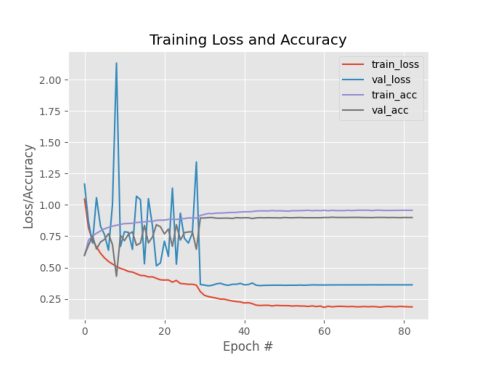

In [32]:
# train
if not residual_CNN.load():
    residual_CNN.train()
residual_CNN.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step


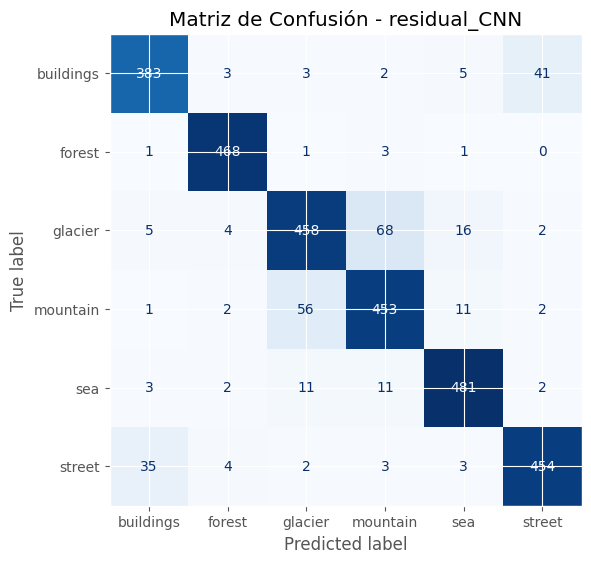

              precision    recall  f1-score   support

   buildings     0.8949    0.8764    0.8855       437
      forest     0.9689    0.9873    0.9781       474
     glacier     0.8625    0.8282    0.8450       553
    mountain     0.8389    0.8629    0.8507       525
         sea     0.9304    0.9431    0.9367       510
      street     0.9062    0.9062    0.9062       501

    accuracy                         0.8990      3000
   macro avg     0.9003    0.9007    0.9004      3000
weighted avg     0.8987    0.8990    0.8987      3000



In [33]:
# Evaluar
y_true, y_pred = residual_CNN.evaluate()
# Matriz de confusion
residual_CNN.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
residual_CNN.print_classification_report(y_true, y_pred)

## 3.Transfer Learning

### 3.1 MobileNetV2

En este apartado se utiliza **MobileNetV2**, una red neuronal convolucional preentrenada. El entrenamiento se divide en dos fases:

3.1.1. **Feature extraction:** se congelan los pesos de MobileNetV2 y se entrenan únicamente las nuevas capas de clasificación.

3.1.2. **Fine-tuning:** se descongelan las últimas capas de la red y se entrenan con una tasa de aprendizaje menor para adaptar mejor el modelo a nuestro problema.

### 3.1.1 Feature extraction

In [34]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

class MobileNetV2_model(base_model):

    def __init__(self, name, epochs, batch_size,
                 train_ds, val_ds, test_ds):

        # Los datasets originales contienen imágenes en [0, 255].
        # MobileNetV2 necesita valores en [-1, 1].
        train_ds = (
            train_ds
            .map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )

        val_ds = (
            val_ds
            .map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )

        test_ds = (
            test_ds
            .map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )

        super().__init__(
            name=name,
            epochs=epochs,
            batch_size=batch_size,
            train_ds=train_ds,
            val_ds=val_ds,
            test_ds=test_ds
        )

        self.base_network = None

    def build(self):

        # Red preentrenada con ImageNet
        self.base_network = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=IMG_SIZE + (3,)
        )

        # Congelamos la red preentrenada
        self.base_network.trainable = False

        inputs = Input(shape=IMG_SIZE + (3,))

        # Extracción de características
        x = self.base_network(inputs, training=False)

        # Nuevas capas de clasificación
        x = GlobalAveragePooling2D()(x)
        x = Dropout(0.2)(x)
        outputs = Dense(
            len(class_names),
            activation="softmax"
        )(x)

        self.model = tf.keras.Model(
            inputs,
            outputs,
            name=self.name
        )

        self.model.compile(
            optimizer=Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        self.model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 65s 118ms/step - accuracy: 0.8549 - loss: 0.3869 - val_accuracy: 0.9027 - val_loss: 0.2673 - learning_rate: 0.0010
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9093 - loss: 0.2408 - val_accuracy: 0.9056 - val_loss: 0.2557 - learning_rate: 0.0010
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9198 - loss: 0.2144 - val_accuracy: 0.9045 - val_loss: 0.2567 - learning_rate: 0.0010
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.9263 - loss: 0.1939 - val_accuracy: 0.9077 - val_loss: 0.2556 - learning_rate: 0.0010
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9304 - loss: 0.1848 - val_accuracy: 0.9070 - val_loss: 0.2588 - learning_rate: 0.0010
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9333 - loss: 0.1765 - val_accuracy: 0.9095 - val_loss: 0.2606 - learning_rate: 0.0010
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9356 - loss:

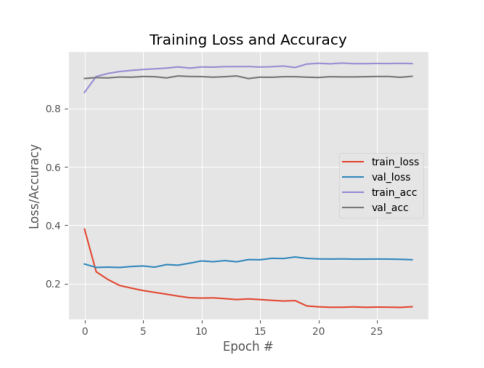

In [35]:
# Crear el modelo MobileNetV2

mobileNetV2 = MobileNetV2_model(
    name="MobileNetV2",
    epochs=30,
    batch_size=BATCH_SIZE,
    train_ds=train_ds,
    val_ds=val_ds,
    test_ds=test_ds
)

mobileNetV2.build()

# Entrenar o recuperar pesos guardados
if not mobileNetV2.load():
    mobileNetV2.train()

# Mostrar evolución del entrenamiento
if (MODELS / "MobileNetV2.png").exists():
    mobileNetV2.show_history()


### 3.1.2 Fine-tuning

Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 1,518,406 (5.79 MB)

 Non-trainable params: 747,264 (2.85 MB)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 61ms/step - accuracy: 0.9425 - loss: 0.1516 - val_accuracy: 0.9127 - val_loss: 0.2651 - learning_rate: 1.0000e-05
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.9530 - loss: 0.1229 - val_accuracy: 0.9098 - val_loss: 0.2703 - learning_rate: 1.0000e-05
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9620 - loss: 0.0968 - val_accuracy: 0.9120 - val_loss: 0.2662 - learning_rate: 1.0000e-05
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.9697 - loss: 0.0802 - val_accuracy: 0.9116 - val_loss: 0.2805 - learning_rate: 1.0000e-05
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9753 - loss: 0.0659 - val_accuracy: 0.9127 - val_loss: 0.2738 - learning_rate: 5.0000e-06
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9806 - loss: 0.0547 - val_accuracy: 0.9120 - val_loss: 0.2816 - learning_rate: 5.0000e-06


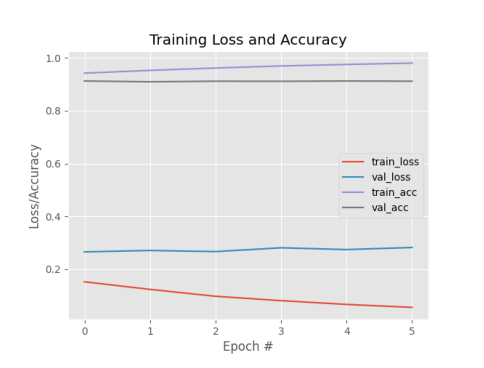

In [36]:
#Fine-tuning de MobileNetV2

fine_tuning_weights = MODELS / "MobileNetV2_finetuned.weights.h5"
fine_tuning_plot = MODELS / "MobileNetV2_finetuned.png"

if fine_tuning_weights.exists():

    # Recuperamos el modelo ya ajustado
    mobileNetV2.base_network.trainable = True

    for layer in mobileNetV2.base_network.layers[:-30]:
        layer.trainable = False

    # Mantenemos congeladas las BatchNormalization
    for layer in mobileNetV2.base_network.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    mobileNetV2.model.load_weights(fine_tuning_weights)
    print("Pesos del fine-tuning recuperados.")

else:

    # Descongelamos únicamente las últimas 30 capas
    mobileNetV2.base_network.trainable = True

    for layer in mobileNetV2.base_network.layers[:-30]:
        layer.trainable = False

    # Las BatchNormalization permanecen congeladas
    for layer in mobileNetV2.base_network.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    # Learning rate menor para no alterar bruscamente
    # los pesos preentrenados
    mobileNetV2.model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    mobileNetV2.model.summary()

    # Entrenamiento con parada anticipada
    history_finetuning = mobileNetV2.model.fit(
        mobileNetV2.train_ds,
        validation_data=mobileNetV2.val_ds,
        epochs=20,
        callbacks=[
            EarlyStopping(
                monitor="val_accuracy",
                patience=5,
                mode="max",
                restore_best_weights=True
            ),
            ReduceLROnPlateau(
                monitor="val_accuracy",
                factor=0.5,
                patience=3,
                mode="max",
                min_lr=1e-7
            )
        ]
    )

    # Guardamos pesos y gráfica por separado
    mobileNetV2.model.save_weights(fine_tuning_weights)

    mobileNetV2.plot_history(history_finetuning)

    # Guardamos la gráfica con otro nombre
    import shutil
    shutil.copyfile(
        MODELS / "MobileNetV2.png",
        fine_tuning_plot
    )

# Mostrar gráfica del fine-tuning si existe
if fine_tuning_plot.exists():
    from PIL import Image
    plt.figure(figsize=(6, 6))
    plt.imshow(Image.open(fine_tuning_plot))
    plt.axis("off")
    plt.show()


94/94 ━━━━━━━━━━━━━━━━━━━━ 16s 167ms/step - accuracy: 0.9197 - loss: 0.2315
Test Loss: 0.2315
Test Accuracy: 0.9197
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step


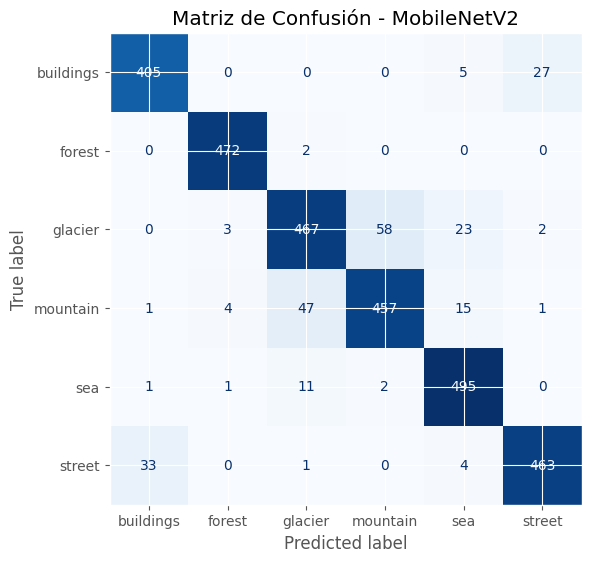

              precision    recall  f1-score   support

   buildings     0.9205    0.9268    0.9236       437
      forest     0.9833    0.9958    0.9895       474
     glacier     0.8845    0.8445    0.8640       553
    mountain     0.8839    0.8705    0.8772       525
         sea     0.9133    0.9706    0.9411       510
      street     0.9391    0.9242    0.9316       501

    accuracy                         0.9197      3000
   macro avg     0.9208    0.9220    0.9212      3000
weighted avg     0.9193    0.9197    0.9192      3000



In [37]:

# Evaluación final de MobileNetV2

loss, accuracy = mobileNetV2.model.evaluate(
    mobileNetV2.test_ds,
    verbose=1
)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Predicciones
y_true, y_pred = mobileNetV2.evaluate()

# Matriz de confusión
mobileNetV2.display_confusion_matrix(y_true, y_pred)

# Informe de clasificación
mobileNetV2.print_classification_report(y_true, y_pred)
